# Exploratory Data Analysis on Retail Sales Data

## Oasis Infobyte — Data Analytics Internship
### Level 1 — Task 1

## Project Objective

The objective of this project is to perform Exploratory Data Analysis (EDA) on a retail sales dataset to identify sales trends, understand customer demographics, evaluate product performance, discover relationships between numerical variables, and develop actionable business recommendations.

The analysis follows a structured data analytics process involving data inspection, cleaning, descriptive statistics, time-series analysis, customer analysis, product analysis, data visualisation and business interpretation.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

pd.set_option("display.max_columns", None)

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
url = "https://raw.githubusercontent.com/Oragant/Retail-Sales-Dashboard/main/retail_sales_dataset.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully.
Dataset shape: (1000, 9)


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


## 1. Initial Data Inspection

Before performing the main analysis, the dataset is inspected to understand its size, structure, column names, data types and overall quality.

This stage helps identify missing values, duplicates or incorrect data types that may affect the reliability of the analysis.

In [3]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nDataset Shape:")
print(df.shape)

Number of rows: 1000
Number of columns: 9

Dataset Shape:
(1000, 9)


In [4]:
print("Column Names:")

for column in df.columns:
    print("-", column)

Column Names:
- Transaction ID
- Date
- Customer ID
- Gender
- Age
- Product Category
- Quantity
- Price per Unit
- Total Amount


In [5]:
df.head(10)

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100
5,6,2023-04-25,CUST006,Female,45,Beauty,1,30,30
6,7,2023-03-13,CUST007,Male,46,Clothing,2,25,50
7,8,2023-02-22,CUST008,Male,30,Electronics,4,25,100
8,9,2023-12-13,CUST009,Male,63,Electronics,2,300,600
9,10,2023-10-07,CUST010,Female,52,Clothing,4,50,200


### Observation

The dataset contains transaction-level retail information including customer demographics, product category, quantity purchased, unit pricing and total transaction value.

These variables make the dataset suitable for analysing customer behaviour, product performance and sales trends.

## 2. Data Type Inspection

Each column is inspected to ensure that its data type is appropriate for the intended analysis.

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    1000 non-null   int64 
 1   Date              1000 non-null   object
 2   Customer ID       1000 non-null   object
 3   Gender            1000 non-null   object
 4   Age               1000 non-null   int64 
 5   Product Category  1000 non-null   object
 6   Quantity          1000 non-null   int64 
 7   Price per Unit    1000 non-null   int64 
 8   Total Amount      1000 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 70.4+ KB


In [7]:
print(df.dtypes)

Transaction ID       int64
Date                object
Customer ID         object
Gender              object
Age                  int64
Product Category    object
Quantity             int64
Price per Unit       int64
Total Amount         int64
dtype: object


In [8]:
df["Date"] = pd.to_datetime(df["Date"])

print("Updated data types:")
print(df.dtypes)

Updated data types:
Transaction ID               int64
Date                datetime64[ns]
Customer ID                 object
Gender                      object
Age                          int64
Product Category            object
Quantity                     int64
Price per Unit               int64
Total Amount                 int64
dtype: object


### Observation

The Date column was originally stored as text and was converted to a datetime data type. This conversion is necessary for monthly and quarterly time-series analysis later in the project.

## 3. Missing Value Analysis

Missing values can affect calculations and visualisations. Each column is therefore checked for null values before continuing with the analysis.

In [9]:
missing_values = df.isnull().sum()

print("Missing Values Per Column:")
print(missing_values)

print("\nTotal Missing Values:")
print(missing_values.sum())

Missing Values Per Column:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

Total Missing Values:
0


In [10]:
missing_percentage = (
    df.isnull().sum() / len(df) * 100
).round(2)

missing_report = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": missing_percentage
})

missing_report

,Missing Values,Missing Percentage
Transaction ID,0,0.0
Date,0,0.0
Customer ID,0,0.0
Gender,0,0.0
Age,0,0.0
Product Category,0,0.0
Quantity,0,0.0
Price per Unit,0,0.0
Total Amount,0,0.0


### Observation


The dataset contains no missing values. Therefore, no missing-value imputation or row removal was required.

## 4. Duplicate Analysis

Duplicate records can distort totals, averages and customer behaviour metrics. The dataset is therefore checked for completely duplicated rows.

In [11]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [12]:
if duplicate_count > 0:
    df = df.drop_duplicates().copy()
    print(f"{duplicate_count} duplicate rows were removed.")
else:
    print("No duplicate rows were found.")

No duplicate rows were found.


## 5. Data Quality Summary

In [13]:
data_quality_summary = pd.DataFrame({
    "Metric": [
        "Rows",
        "Columns",
        "Missing Values",
        "Duplicate Rows",
        "Unique Customers",
        "Earliest Transaction Date",
        "Latest Transaction Date"
    ],
    "Result": [
        len(df),
        len(df.columns),
        df.isnull().sum().sum(),
        df.duplicated().sum(),
        df["Customer ID"].nunique(),
        df["Date"].min().date(),
        df["Date"].max().date()
    ]
})

data_quality_summary

,Metric,Result
0,Rows,1000
1,Columns,9
2,Missing Values,0
3,Duplicate Rows,0
4,Unique Customers,1000
5,Earliest Transaction Date,2023-01-01
6,Latest Transaction Date,2024-01-01


## 6. Descriptive Statistics

Descriptive statistics provide an overview of the numerical characteristics of the dataset.

The mean describes the average value, the median describes the midpoint, the mode identifies the most frequently occurring value, and the standard deviation measures the spread of the data.

In [14]:
df.describe()

,Transaction ID,Date,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,2023-07-03 00:25:55.200000256,41.39200,2.514000,179.890000,456.000000
min,1.000000,2023-01-01 00:00:00,18.00000,1.000000,25.000000,25.000000
25%,250.750000,2023-04-08 00:00:00,29.00000,1.000000,30.000000,60.000000
50%,500.500000,2023-06-29 12:00:00,42.00000,3.000000,50.000000,135.000000
75%,750.250000,2023-10-04 00:00:00,53.00000,4.000000,300.000000,900.000000
max,1000.000000,2024-01-01 00:00:00,64.00000,4.000000,500.000000,2000.000000
std,288.819436,NaN,13.68143,1.132734,189.681356,559.997632


In [15]:
numeric_columns = [
    "Age",
    "Quantity",
    "Price per Unit",
    "Total Amount"
]

summary_statistics = pd.DataFrame({
    "Mean": df[numeric_columns].mean(),
    "Median": df[numeric_columns].median(),
    "Mode": df[numeric_columns].mode().iloc[0],
    "Standard Deviation": df[numeric_columns].std(),
    "Minimum": df[numeric_columns].min(),
    "Maximum": df[numeric_columns].max()
})

summary_statistics.round(2)

,Mean,Median,Mode,Standard Deviation,Minimum,Maximum
Age,41.39,42.0,43.0,13.68,18,64
Quantity,2.51,3.0,4.0,1.13,1,4
Price per Unit,179.89,50.0,50.0,189.68,25,500
Total Amount,456.00,135.0,50.0,560.00,25,2000


## 7. Retail Performance Overview

Several high-level retail performance indicators are calculated to provide a quick summary of the dataset before conducting deeper analysis.

In [16]:
total_revenue = df["Total Amount"].sum()
total_transactions = df["Transaction ID"].nunique()
total_units_sold = df["Quantity"].sum()
average_transaction_value = df["Total Amount"].mean()
unique_customers = df["Customer ID"].nunique()

print("========== RETAIL PERFORMANCE OVERVIEW ==========")

print(f"Total Revenue: {total_revenue:,.2f}")
print(f"Total Transactions: {total_transactions:,}")
print(f"Total Units Sold: {total_units_sold:,}")
print(f"Average Transaction Value: {average_transaction_value:,.2f}")
print(f"Unique Customers: {unique_customers:,}")

========== RETAIL PERFORMANCE OVERVIEW ==========
Total Revenue: 456,000.00
Total Transactions: 1,000
Total Units Sold: 2,514
Average Transaction Value: 456.00
Unique Customers: 1,000


In [17]:
performance_summary = pd.DataFrame({
    "Metric": [
        "Total Revenue",
        "Total Transactions",
        "Total Units Sold",
        "Average Transaction Value",
        "Unique Customers"
    ],
    "Value": [
        round(total_revenue, 2),
        total_transactions,
        total_units_sold,
        round(average_transaction_value, 2),
        unique_customers
    ]
})

performance_summary

,Metric,Value
0,Total Revenue,456000.0
1,Total Transactions,1000.0
2,Total Units Sold,2514.0
3,Average Transaction Value,456.0
4,Unique Customers,1000.0


## 8. Sales Trend Analysis

Sales are analysed over time to identify changes in performance, stronger and weaker periods, and possible seasonal patterns.

In [18]:
df["Month"] = df["Date"].dt.to_period("M")
df["Quarter"] = df["Date"].dt.to_period("Q")

df[["Date", "Month", "Quarter"]].head()

,Date,Month,Quarter
0,2023-11-24,2023-11,2023Q4
1,2023-02-27,2023-02,2023Q1
2,2023-01-13,2023-01,2023Q1
3,2023-05-21,2023-05,2023Q2
4,2023-05-06,2023-05,2023Q2


In [19]:
monthly_sales = (
    df.groupby("Month")["Total Amount"]
    .sum()
    .sort_index()
)

monthly_sales

,Total Amount
Month,
2023-01,35450
2023-02,44060
2023-03,28990
2023-04,33870
2023-05,53150
2023-06,36715
2023-07,35465
2023-08,36960
2023-09,23620


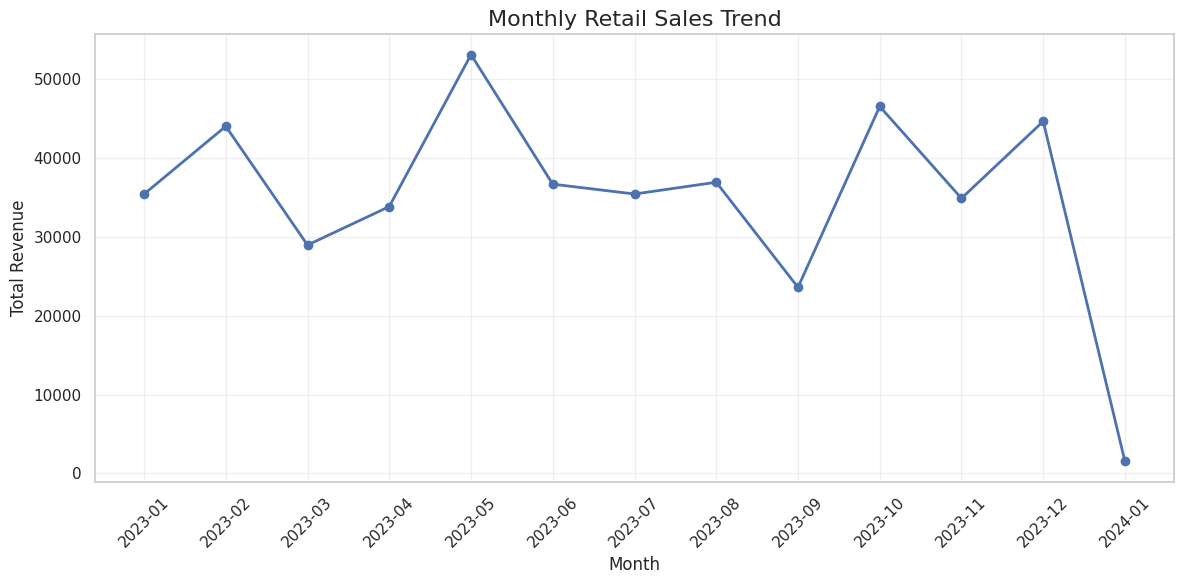

In [20]:
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_sales.index.astype(str),
    monthly_sales.values,
    marker="o",
    linewidth=2
)

plt.title("Monthly Retail Sales Trend", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

### Observation

The monthly sales chart shows that revenue changes across the year rather than remaining constant. This indicates that purchasing activity varies between months.

The strongest and weakest months will be identified quantitatively later in the analysis to support business planning and promotional decisions.

In [21]:
best_month = monthly_sales.idxmax()
best_month_revenue = monthly_sales.max()

worst_month = monthly_sales.idxmin()
worst_month_revenue = monthly_sales.min()

print(f"Best Sales Month: {best_month}")
print(f"Revenue in Best Month: {best_month_revenue:,.2f}")

print()

print(f"Worst Sales Month: {worst_month}")
print(f"Revenue in Worst Month: {worst_month_revenue:,.2f}")

Best Sales Month: 2023-05
Revenue in Best Month: 53,150.00

Worst Sales Month: 2024-01
Revenue in Worst Month: 1,530.00


In [22]:
quarterly_sales = (
    df.groupby("Quarter")["Total Amount"]
    .sum()
    .sort_index()
)

quarterly_sales

,Total Amount
Quarter,
2023Q1,108500
2023Q2,123735
2023Q3,96045
2023Q4,126190
2024Q1,1530


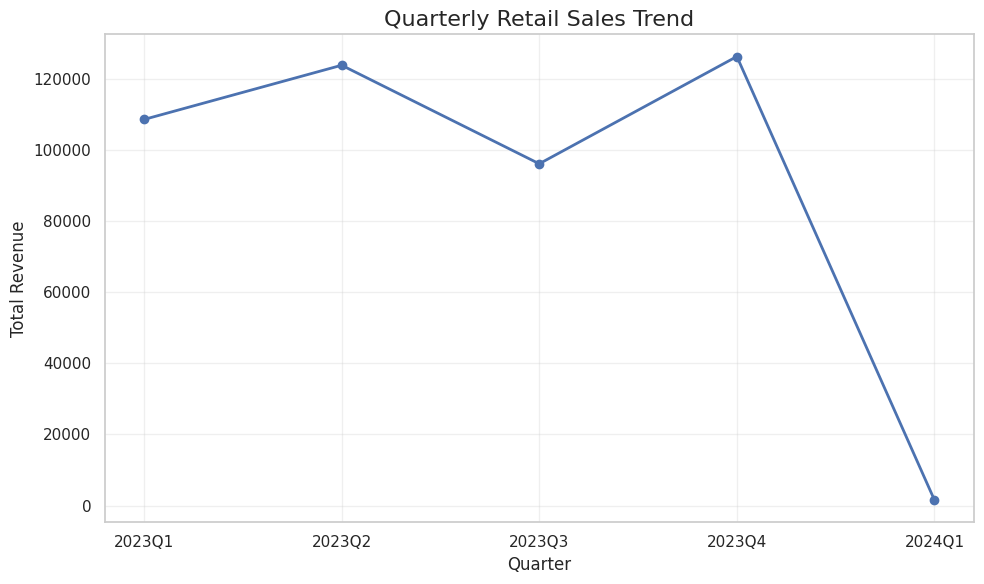

In [23]:
plt.figure(figsize=(10, 6))

plt.plot(
    quarterly_sales.index.astype(str),
    quarterly_sales.values,
    marker="o",
    linewidth=2
)

plt.title("Quarterly Retail Sales Trend", fontsize=16)
plt.xlabel("Quarter")
plt.ylabel("Total Revenue")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

### Observation

Quarterly analysis provides a broader view of revenue performance than individual monthly results.

Comparing quarters helps management identify stronger periods and can support decisions related to inventory levels, staffing and promotional activity.

In [24]:
best_quarter = quarterly_sales.idxmax()
best_quarter_revenue = quarterly_sales.max()

worst_quarter = quarterly_sales.idxmin()
worst_quarter_revenue = quarterly_sales.min()

print(f"Best Quarter: {best_quarter}")
print(f"Revenue in Best Quarter: {best_quarter_revenue:,.2f}")

print()

print(f"Worst Quarter: {worst_quarter}")
print(f"Revenue in Worst Quarter: {worst_quarter_revenue:,.2f}")

Best Quarter: 2023Q4
Revenue in Best Quarter: 126,190.00

Worst Quarter: 2024Q1
Revenue in Worst Quarter: 1,530.00


## 9. Customer Demographic Analysis

Customer demographics are analysed to understand the characteristics of the customer base and identify differences in transaction activity between customer groups.

In [25]:
gender_counts = df["Gender"].value_counts()

gender_counts

,count
Gender,
Female,510
Male,490


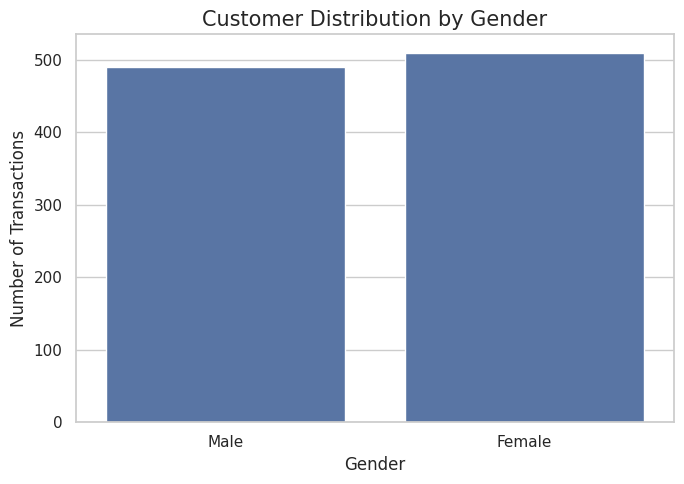

In [26]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Gender"
)

plt.title("Customer Distribution by Gender", fontsize=15)
plt.xlabel("Gender")
plt.ylabel("Number of Transactions")
plt.tight_layout()

plt.show()

### Observation

The gender distribution chart compares the number of transactions associated with each gender group.

This helps determine whether one demographic group is more strongly represented in the dataset and provides useful context for customer segmentation and marketing analysis.

In [27]:
gender_revenue = (
    df.groupby("Gender")["Total Amount"]
    .sum()
    .sort_values(ascending=False)
)

gender_revenue

,Total Amount
Gender,
Female,232840
Male,223160


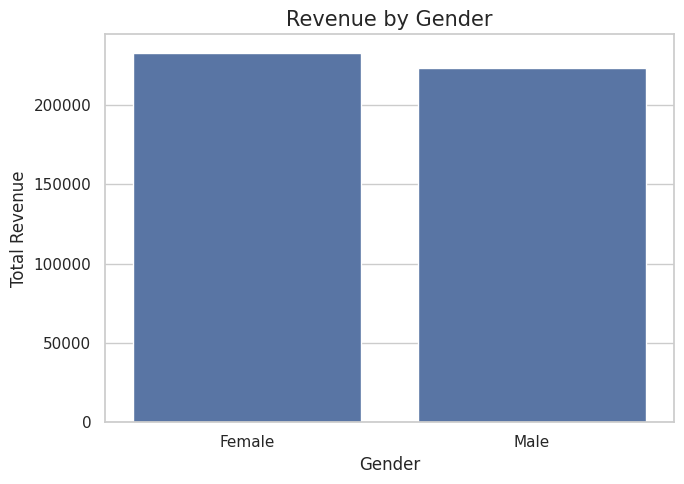

In [28]:
plt.figure(figsize=(7, 5))

sns.barplot(
    x=gender_revenue.index,
    y=gender_revenue.values
)

plt.title("Revenue by Gender", fontsize=15)
plt.xlabel("Gender")
plt.ylabel("Total Revenue")
plt.tight_layout()

plt.show()

### Observation

Revenue by gender provides a more useful commercial comparison than transaction counts alone.

A group may represent a similar number of transactions but still generate a different level of total revenue depending on purchasing value.

In [29]:
print("Youngest Customer:", df["Age"].min())
print("Oldest Customer:", df["Age"].max())
print("Average Customer Age:", round(df["Age"].mean(), 2))
print("Median Customer Age:", df["Age"].median())

Youngest Customer: 18
Oldest Customer: 64
Average Customer Age: 41.39
Median Customer Age: 42.0


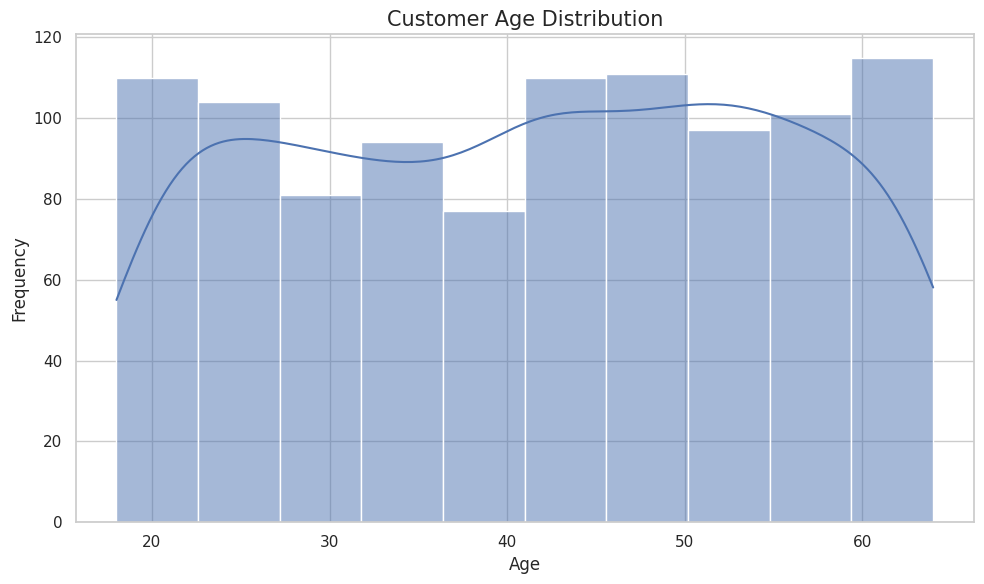

In [30]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="Age",
    bins=10,
    kde=True
)

plt.title("Customer Age Distribution", fontsize=15)
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.tight_layout()

plt.show()

### Observation

The age distribution shows how customers are spread across different age ranges.

This helps identify whether the customer base is concentrated around younger, middle-aged or older consumers.

In [31]:
age_bins = [17, 24, 34, 44, 54, 64, 100]

age_labels = [
    "18-24",
    "25-34",
    "35-44",
    "45-54",
    "55-64",
    "65+"
]

df["Age Group"] = pd.cut(
    df["Age"],
    bins=age_bins,
    labels=age_labels
)

df[["Age", "Age Group"]].head(10)

,Age,Age Group
0,34,25-34
1,26,25-34
2,50,45-54
3,37,35-44
4,30,25-34
5,45,45-54
6,46,45-54
7,30,25-34
8,63,55-64
9,52,45-54


In [32]:
age_group_counts = (
    df["Age Group"]
    .value_counts()
    .sort_index()
)

age_group_counts

,count
Age Group,
18-24,149
25-34,203
35-44,207
45-54,225
55-64,216
65+,0


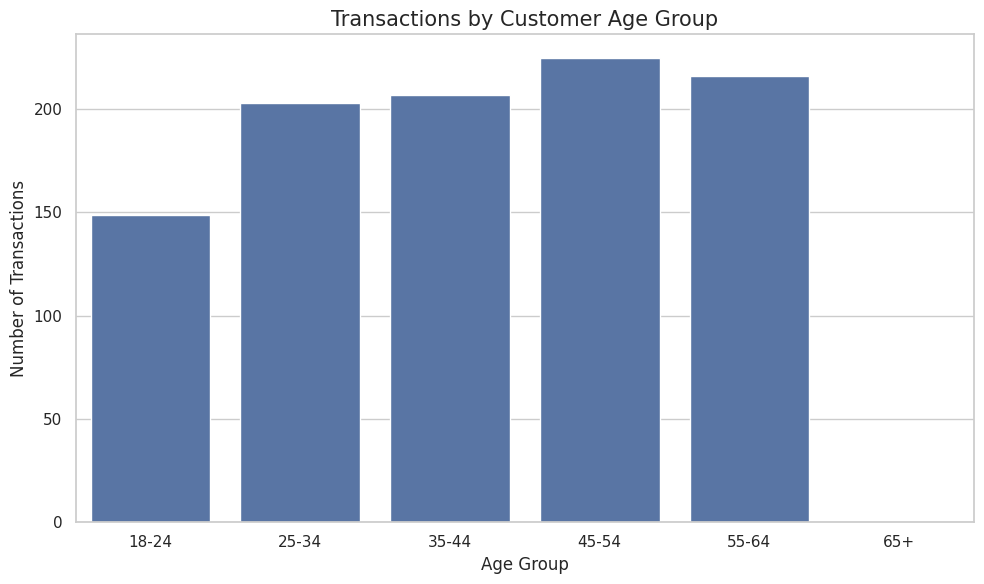

In [33]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=age_group_counts.index,
    y=age_group_counts.values
)

plt.title("Transactions by Customer Age Group", fontsize=15)
plt.xlabel("Age Group")
plt.ylabel("Number of Transactions")
plt.tight_layout()

plt.show()

### Observation

Grouping customers into age categories makes the demographic pattern easier to interpret.

The chart shows which customer age groups appear most frequently in the retail transactions and can help guide targeted marketing decisions.

In [34]:
age_group_revenue = (
    df.groupby("Age Group", observed=False)["Total Amount"]
    .sum()
)

age_group_revenue

,Total Amount
Age Group,
18-24,74650
25-34,97090
35-44,96835
45-54,97235
55-64,90190
65+,0


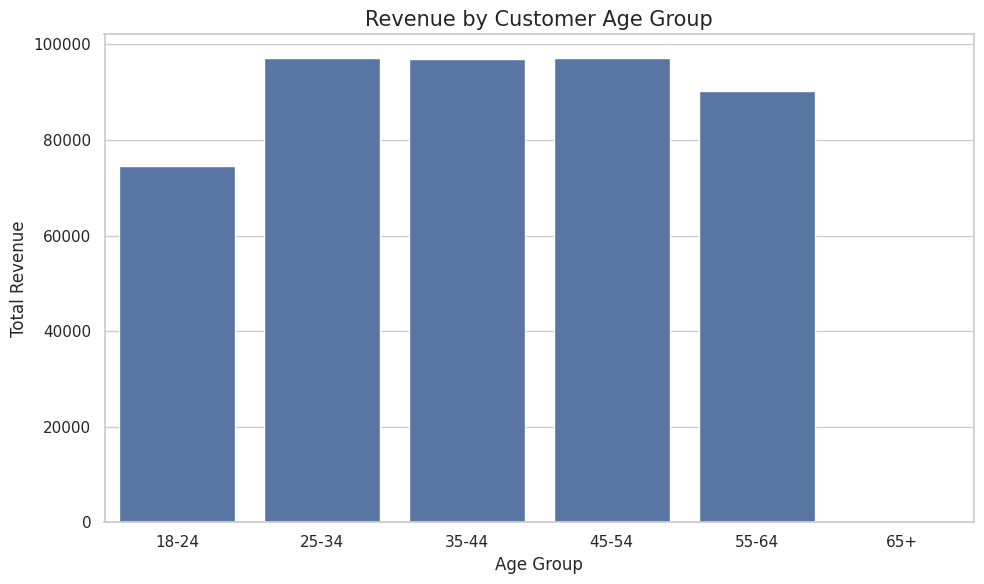

In [35]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=age_group_revenue.index,
    y=age_group_revenue.values
)

plt.title("Revenue by Customer Age Group", fontsize=15)
plt.xlabel("Age Group")
plt.ylabel("Total Revenue")
plt.tight_layout()

plt.show()

### Observation

Revenue by age group identifies which customer segments contribute the greatest amount of sales revenue.

This information can help a retailer prioritise customer segments when developing advertising, loyalty programmes and promotional campaigns.

In [36]:
top_age_group = age_group_revenue.idxmax()
top_age_group_revenue = age_group_revenue.max()

lowest_age_group = age_group_revenue.idxmin()
lowest_age_group_revenue = age_group_revenue.min()

print(f"Highest Revenue Age Group: {top_age_group}")
print(f"Revenue: {top_age_group_revenue:,.2f}")

print()

print(f"Lowest Revenue Age Group: {lowest_age_group}")
print(f"Revenue: {lowest_age_group_revenue:,.2f}")

Highest Revenue Age Group: 45-54
Revenue: 97,235.00

Lowest Revenue Age Group: 65+
Revenue: 0.00


In [37]:
age_group_average_spend = (
    df.groupby("Age Group", observed=False)["Total Amount"]
    .mean()
    .sort_values(ascending=False)
)

age_group_average_spend

,Total Amount
Age Group,
18-24,501.006711
25-34,478.275862
35-44,467.801932
45-54,432.155556
55-64,417.546296
65+,NaN


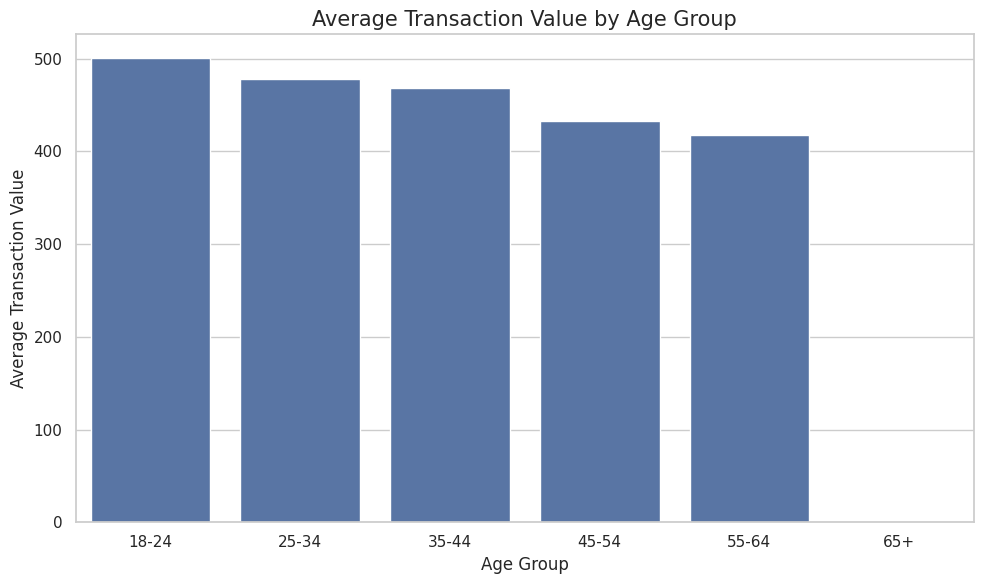

In [38]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=age_group_average_spend.index,
    y=age_group_average_spend.values
)

plt.title("Average Transaction Value by Age Group", fontsize=15)
plt.xlabel("Age Group")
plt.ylabel("Average Transaction Value")
plt.tight_layout()

plt.show()

### Observation

Average transaction value shows how much each age group spends per transaction on average.

This helps distinguish between customer groups that generate high total revenue because they appear frequently and groups that individually make higher-value purchases.

In [39]:
print("========== SALES AND CUSTOMER SUMMARY ==========")

print(f"Best Sales Month: {best_month}")
print(f"Best Month Revenue: {best_month_revenue:,.2f}")

print()

print(f"Worst Sales Month: {worst_month}")
print(f"Worst Month Revenue: {worst_month_revenue:,.2f}")

print()

print(f"Best Quarter: {best_quarter}")
print(f"Best Quarter Revenue: {best_quarter_revenue:,.2f}")

print()

print(f"Highest Revenue Age Group: {top_age_group}")
print(f"Age Group Revenue: {top_age_group_revenue:,.2f}")

print()

print("Revenue by Gender:")
print(gender_revenue)

========== SALES AND CUSTOMER SUMMARY ==========
Best Sales Month: 2023-05
Best Month Revenue: 53,150.00

Worst Sales Month: 2024-01
Worst Month Revenue: 1,530.00

Best Quarter: 2023Q4
Best Quarter Revenue: 126,190.00

Highest Revenue Age Group: 45-54
Age Group Revenue: 97,235.00

Revenue by Gender:
Gender
Female    232840
Male      223160
Name: Total Amount, dtype: int64


## 10. Product Performance Analysis

Product performance is analysed using both total revenue and total quantity sold.

This distinction is important because a category can sell many units without necessarily generating the highest revenue, while another category may generate greater revenue from fewer units because of higher prices.

In [40]:
category_revenue = (
    df.groupby("Product Category")["Total Amount"]
    .sum()
    .sort_values(ascending=False)
)

category_revenue

,Total Amount
Product Category,
Electronics,156905
Clothing,155580
Beauty,143515


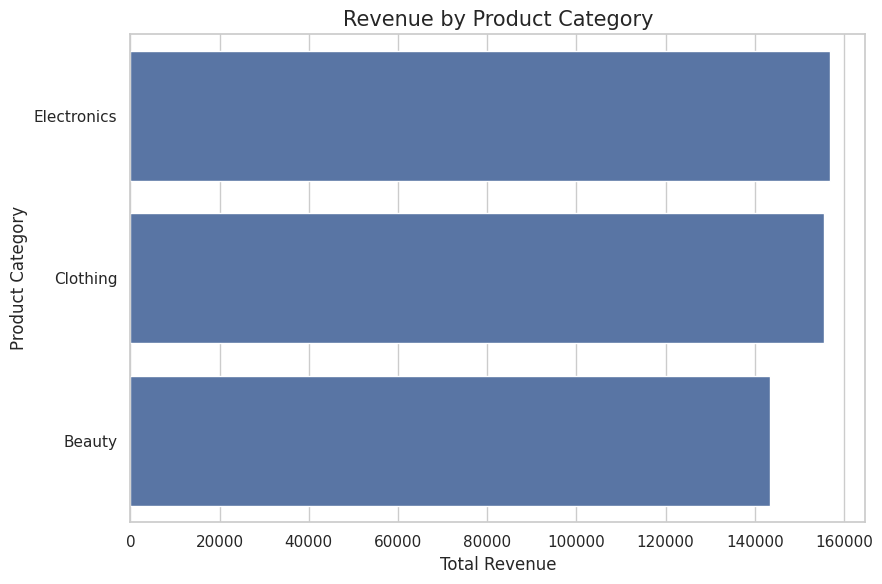

In [41]:
plt.figure(figsize=(9, 6))

sns.barplot(
    x=category_revenue.values,
    y=category_revenue.index
)

plt.title("Revenue by Product Category", fontsize=15)
plt.xlabel("Total Revenue")
plt.ylabel("Product Category")
plt.tight_layout()

plt.show()

### Observation

The revenue analysis compares the total sales value generated by each product category.

This provides management with a clear view of which categories contribute most strongly to overall revenue and which categories contribute less.

In [42]:
highest_revenue_category = category_revenue.idxmax()
highest_revenue_value = category_revenue.max()

lowest_revenue_category = category_revenue.idxmin()
lowest_revenue_value = category_revenue.min()

print(f"Highest Revenue Category: {highest_revenue_category}")
print(f"Revenue: {highest_revenue_value:,.2f}")

print()

print(f"Lowest Revenue Category: {lowest_revenue_category}")
print(f"Revenue: {lowest_revenue_value:,.2f}")

Highest Revenue Category: Electronics
Revenue: 156,905.00

Lowest Revenue Category: Beauty
Revenue: 143,515.00


In [43]:
category_quantity = (
    df.groupby("Product Category")["Quantity"]
    .sum()
    .sort_values(ascending=False)
)

category_quantity

,Quantity
Product Category,
Clothing,894
Electronics,849
Beauty,771


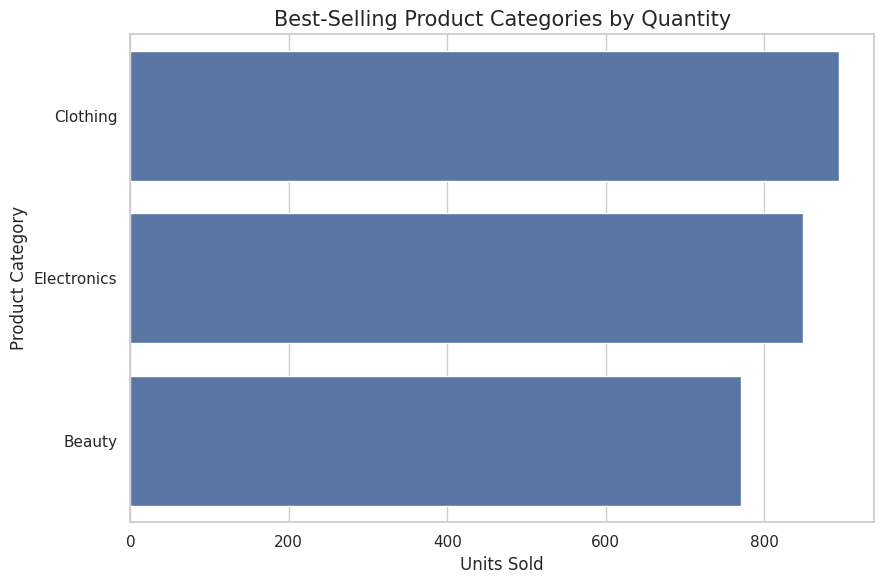

In [44]:
plt.figure(figsize=(9, 6))

sns.barplot(
    x=category_quantity.values,
    y=category_quantity.index
)

plt.title("Best-Selling Product Categories by Quantity", fontsize=15)
plt.xlabel("Units Sold")
plt.ylabel("Product Category")
plt.tight_layout()

plt.show()

### Observation

Quantity-based analysis identifies which product categories sell the greatest number of units.

This should be considered alongside revenue because the category with the highest unit sales may not necessarily be the category generating the highest sales value.

In [45]:
highest_quantity_category = category_quantity.idxmax()
highest_quantity_value = category_quantity.max()

lowest_quantity_category = category_quantity.idxmin()
lowest_quantity_value = category_quantity.min()

print(f"Highest-Selling Category: {highest_quantity_category}")
print(f"Units Sold: {highest_quantity_value:,.0f}")

print()

print(f"Lowest-Selling Category: {lowest_quantity_category}")
print(f"Units Sold: {lowest_quantity_value:,.0f}")

Highest-Selling Category: Clothing
Units Sold: 894

Lowest-Selling Category: Beauty
Units Sold: 771


## 11. Average Transaction Value by Product Category

Average transaction value is analysed to understand whether certain product categories tend to generate higher-value purchases per transaction.

In [46]:
category_average_transaction = (
    df.groupby("Product Category")["Total Amount"]
    .mean()
    .sort_values(ascending=False)
)

category_average_transaction

,Total Amount
Product Category,
Beauty,467.475570
Electronics,458.786550
Clothing,443.247863


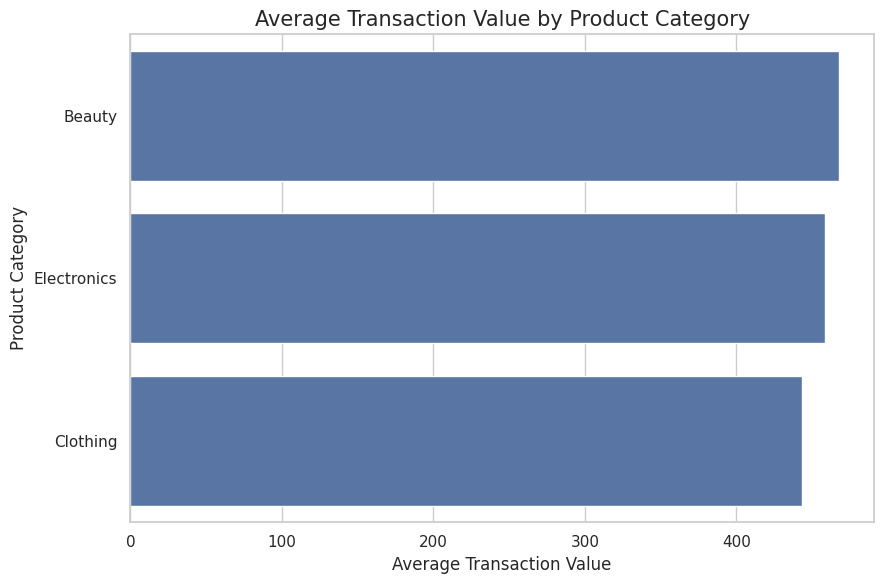

In [47]:
plt.figure(figsize=(9, 6))

sns.barplot(
    x=category_average_transaction.values,
    y=category_average_transaction.index
)

plt.title("Average Transaction Value by Product Category", fontsize=15)
plt.xlabel("Average Transaction Value")
plt.ylabel("Product Category")
plt.tight_layout()

plt.show()

### Observation

Average transaction value provides another view of product performance.

A category may generate strong total revenue because it is purchased frequently, while another category may generate fewer transactions but higher-value purchases.

## 12. Correlation Analysis

Correlation analysis is used to examine the strength and direction of relationships between numerical variables.

Correlation values range from -1 to +1.

- Values close to +1 indicate a strong positive relationship.
- Values close to -1 indicate a strong negative relationship.
- Values close to 0 indicate little or no linear relationship.

In [48]:
correlation_columns = [
    "Age",
    "Quantity",
    "Price per Unit",
    "Total Amount"
]

correlation_matrix = df[correlation_columns].corr()

correlation_matrix.round(2)

,Age,Quantity,Price per Unit,Total Amount
Age,1.00,-0.02,-0.04,-0.06
Quantity,-0.02,1.00,0.02,0.37
Price per Unit,-0.04,0.02,1.00,0.85
Total Amount,-0.06,0.37,0.85,1.00


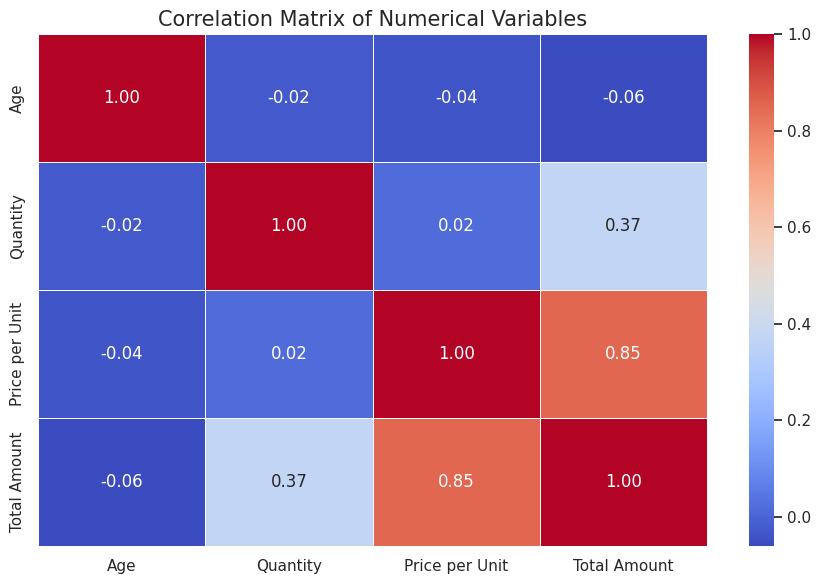

In [49]:
plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix of Numerical Variables", fontsize=15)
plt.tight_layout()

plt.show()

### Observation

The correlation heatmap shows how strongly the numerical variables move together.

The analysis is particularly useful for examining whether transaction value is associated with quantity purchased, unit price or customer age.

## 13. Additional Insight — Quantity Purchased vs Transaction Value

A scatter plot is used to examine whether transactions involving a larger number of units are generally associated with higher transaction values.

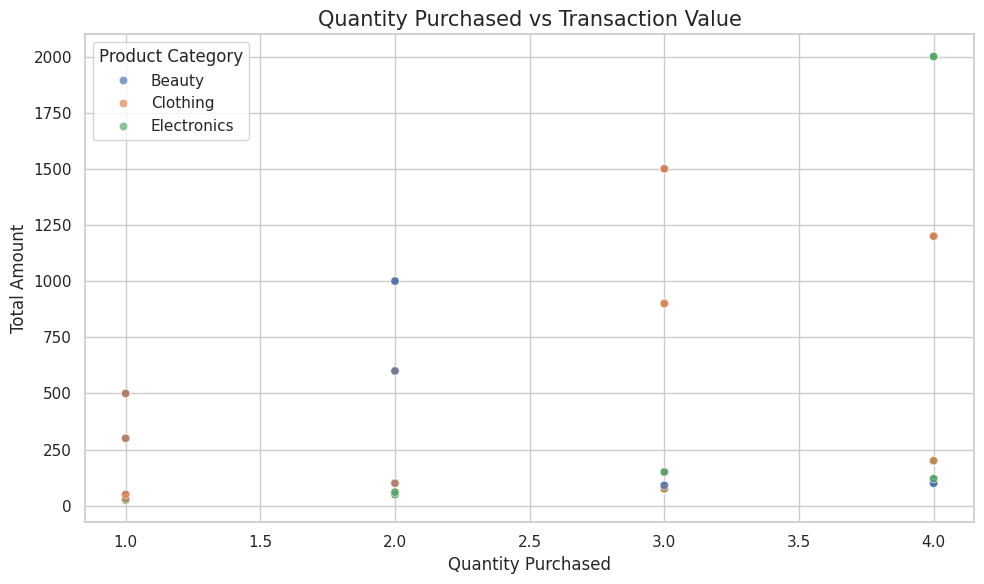

In [50]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Quantity",
    y="Total Amount",
    hue="Product Category",
    alpha=0.7
)

plt.title("Quantity Purchased vs Transaction Value", fontsize=15)
plt.xlabel("Quantity Purchased")
plt.ylabel("Total Amount")
plt.tight_layout()

plt.show()

### Observation

The scatter plot compares quantity purchased with total transaction value across product categories.

The relationship between these variables can help determine whether transaction value is driven primarily by purchasing more units, higher unit prices, or a combination of both.

## 14. Price per Unit vs Transaction Value

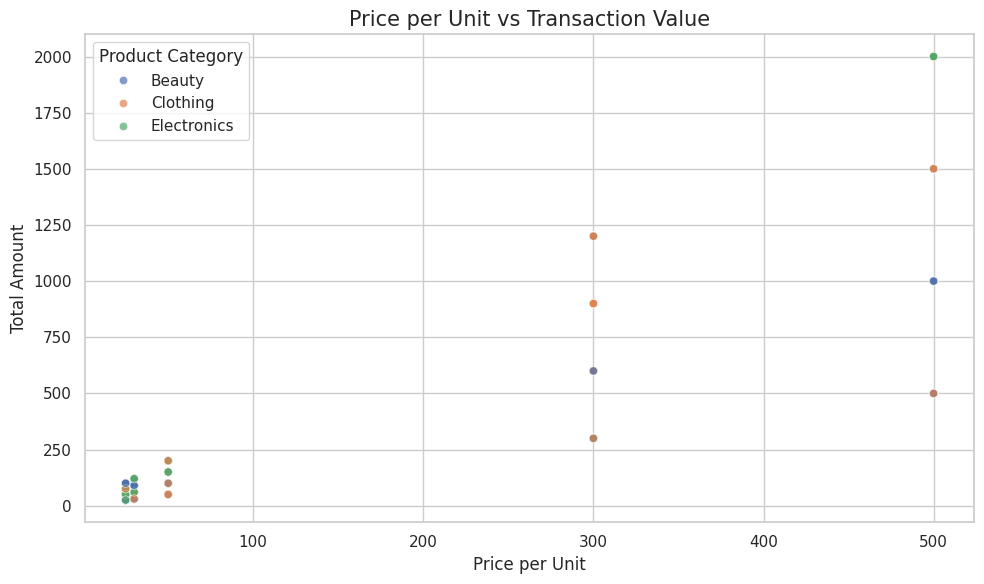

In [51]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Price per Unit",
    y="Total Amount",
    hue="Product Category",
    alpha=0.7
)

plt.title("Price per Unit vs Transaction Value", fontsize=15)
plt.xlabel("Price per Unit")
plt.ylabel("Total Amount")
plt.tight_layout()

plt.show()

### Observation

This analysis examines whether higher-priced products tend to generate larger transaction values.

Comparing unit price with total transaction amount also helps separate the influence of price from the influence of quantity purchased.

In [52]:
product_summary = pd.DataFrame({
    "Total Revenue": df.groupby("Product Category")["Total Amount"].sum(),
    "Units Sold": df.groupby("Product Category")["Quantity"].sum(),
    "Average Transaction Value": df.groupby("Product Category")["Total Amount"].mean(),
    "Average Unit Price": df.groupby("Product Category")["Price per Unit"].mean()
})

product_summary = product_summary.sort_values(
    "Total Revenue",
    ascending=False
)

product_summary.round(2)

,Total Revenue,Units Sold,Average Transaction Value,Average Unit Price
Product Category,,,,
Electronics,156905,849,458.79,181.90
Clothing,155580,894,443.25,174.29
Beauty,143515,771,467.48,184.06


In [53]:
best_month = monthly_sales.idxmax()
best_month_revenue = monthly_sales.max()

worst_month = monthly_sales.idxmin()
worst_month_revenue = monthly_sales.min()

best_quarter = quarterly_sales.idxmax()
best_quarter_revenue = quarterly_sales.max()

worst_quarter = quarterly_sales.idxmin()
worst_quarter_revenue = quarterly_sales.min()

highest_revenue_category = category_revenue.idxmax()
highest_revenue_value = category_revenue.max()

highest_quantity_category = category_quantity.idxmax()
highest_quantity_value = category_quantity.max()

highest_value_category = category_average_transaction.idxmax()
highest_value_category_amount = category_average_transaction.max()

top_age_group = age_group_revenue.idxmax()
top_age_group_revenue = age_group_revenue.max()

top_average_spend_age_group = age_group_average_spend.idxmax()
top_average_spend = age_group_average_spend.max()

print("========== KEY BUSINESS FINDINGS ==========")

print()

print("SALES PERFORMANCE")
print("-----------------")
print(f"Best Month: {best_month} | Revenue: {best_month_revenue:,.2f}")
print(f"Worst Month: {worst_month} | Revenue: {worst_month_revenue:,.2f}")
print(f"Best Quarter: {best_quarter} | Revenue: {best_quarter_revenue:,.2f}")
print(f"Worst Quarter: {worst_quarter} | Revenue: {worst_quarter_revenue:,.2f}")

print()

print("PRODUCT PERFORMANCE")
print("-------------------")
print(
    f"Highest Revenue Category: "
    f"{highest_revenue_category} | "
    f"Revenue: {highest_revenue_value:,.2f}"
)

print(
    f"Highest-Selling Category: "
    f"{highest_quantity_category} | "
    f"Units: {highest_quantity_value:,.0f}"
)

print(
    f"Highest Average Transaction Category: "
    f"{highest_value_category} | "
    f"Average Transaction: {highest_value_category_amount:,.2f}"
)

print()

print("CUSTOMER PERFORMANCE")
print("--------------------")
print(
    f"Highest Revenue Age Group: "
    f"{top_age_group} | "
    f"Revenue: {top_age_group_revenue:,.2f}"
)

print(
    f"Highest Average Spending Age Group: "
    f"{top_average_spend_age_group} | "
    f"Average Transaction: {top_average_spend:,.2f}"
)

print()

print("REVENUE BY GENDER")
print("-----------------")
print(gender_revenue)

========== KEY BUSINESS FINDINGS ==========

SALES PERFORMANCE
-----------------
Best Month: 2023-05 | Revenue: 53,150.00
Worst Month: 2024-01 | Revenue: 1,530.00
Best Quarter: 2023Q4 | Revenue: 126,190.00
Worst Quarter: 2024Q1 | Revenue: 1,530.00

PRODUCT PERFORMANCE
-------------------
Highest Revenue Category: Electronics | Revenue: 156,905.00
Highest-Selling Category: Clothing | Units: 894
Highest Average Transaction Category: Beauty | Average Transaction: 467.48

CUSTOMER PERFORMANCE
--------------------
Highest Revenue Age Group: 45-54 | Revenue: 97,235.00
Highest Average Spending Age Group: 18-24 | Average Transaction: 501.01

REVENUE BY GENDER
-----------------
Gender
Female    232840
Male      223160
Name: Total Amount, dtype: int64


In [54]:
executive_summary = pd.DataFrame({
    "Metric": [
        "Total Revenue",
        "Total Transactions",
        "Total Units Sold",
        "Average Transaction Value",
        "Best Sales Month",
        "Best Quarter",
        "Highest Revenue Product Category",
        "Highest-Selling Product Category",
        "Highest Revenue Age Group"
    ],
    "Result": [
        f"{df['Total Amount'].sum():,.2f}",
        f"{df['Transaction ID'].nunique():,}",
        f"{df['Quantity'].sum():,}",
        f"{df['Total Amount'].mean():,.2f}",
        str(best_month),
        str(best_quarter),
        highest_revenue_category,
        highest_quantity_category,
        str(top_age_group)
    ]
})

executive_summary

,Metric,Result
0,Total Revenue,"456,000.00"
1,Total Transactions,"1,000"
2,Total Units Sold,"2,514"
3,Average Transaction Value,456.00
4,Best Sales Month,2023-05
5,Best Quarter,2023Q4
6,Highest Revenue Product Category,Electronics
7,Highest-Selling Product Category,Clothing
8,Highest Revenue Age Group,45-54


# 15. Executive Analysis and Key Findings

The retail dataset contains 1,000 transactions representing 2,514 units sold and total revenue of 456,000.

The average transaction generated 456 in revenue.

Several important business patterns emerged from the exploratory analysis.

## Sales Performance

May 2023 was the strongest individual sales month in the dataset, while Q4 2023 generated the strongest quarterly performance.

This suggests that sales performance varies meaningfully throughout the year and that management should consider both monthly and quarterly patterns when planning inventory, marketing campaigns and operational resources.

## Product Performance

Electronics generated the highest total revenue of all product categories.

However, Clothing recorded the highest quantity of units sold.

This is an important distinction. Clothing appears to perform strongly in terms of sales volume, while Electronics contributes more strongly to revenue. Management should therefore avoid evaluating product performance using only one metric.

Revenue, units sold, average transaction value and pricing should be considered together when making product and inventory decisions.

## Customer Demographics

Customers aged 45–54 generated the highest total revenue among the analysed age groups.

This indicates that this segment represents an important customer group within the dataset and may be particularly valuable for targeted promotions, loyalty strategies and customer retention activities.

However, demographic targeting should not focus exclusively on this group. Other age segments should continue to be analysed for growth opportunities and differences in average spending behaviour.

# 16. Business Recommendations

## Recommendation 1 — Protect Electronics Revenue

Electronics generated the highest total revenue in the dataset.

The business should ensure that popular electronics products remain adequately stocked, particularly during stronger sales periods. Marketing resources can also be allocated toward high-performing electronics products where the expected revenue contribution justifies the investment.

Management should continue monitoring both unit sales and transaction value because high electronics revenue may be influenced by higher product prices rather than simply higher sales volume.

## Recommendation 2 — Use Clothing as a Volume Driver

Clothing recorded the highest quantity of units sold.

This suggests that Clothing plays an important role in generating transaction volume and customer activity.

The business could use popular clothing products in promotional campaigns, bundles or cross-selling strategies to encourage customers to purchase additional products from higher-value categories.

## Recommendation 3 — Prioritise the 45–54 Customer Segment

Customers aged 45–54 generated the highest total revenue among the analysed age groups.

Marketing campaigns, loyalty programmes and personalised product recommendations could therefore be designed to strengthen engagement with this valuable customer segment.

At the same time, the business should investigate whether younger or older groups represent opportunities for future growth.

## Recommendation 4 — Prepare for Strong Sales Periods

May 2023 was the strongest individual sales month, while Q4 was the strongest quarter.

Historical sales patterns should therefore be considered when planning inventory, staffing and promotional activity.

Management should increase readiness before historically stronger periods to reduce the risk of stock shortages and missed sales opportunities.

## Recommendation 5 — Evaluate Revenue and Volume Together

The fact that Electronics generated the highest revenue while Clothing generated the highest sales volume demonstrates why product performance should not be measured using a single metric.

Future reporting should monitor at least:

- Total revenue
- Units sold
- Average transaction value
- Average unit price

Using these measures together will provide management with a more complete understanding of product performance.

# 17. Conclusion

This exploratory data analysis transformed raw retail transaction data into a structured view of sales performance, customer behaviour and product performance.

The dataset generated total revenue of 456,000 from 1,000 transactions and 2,514 units sold, with an average transaction value of 456.

The analysis found that May 2023 was the strongest individual sales month and Q4 was the strongest quarter.

Product analysis revealed an important difference between revenue and sales volume. Electronics generated the highest total revenue, whereas Clothing recorded the highest number of units sold.

Customer demographic analysis identified the 45–54 age group as the highest-revenue customer segment.

These findings demonstrate how exploratory data analysis can support practical business decisions involving inventory planning, marketing segmentation, product strategy and sales planning.

Further analysis could incorporate additional customer characteristics, product-level information, profit margins and multi-year transaction data to provide deeper insight into long-term retail performance.